# Visualizations: Toxoplasma datasets by source

All charts for the 44 datasets in one place. Reads the results and processed files written by the folder notebooks
(`<folder>/results.csv`, `<folder>/processed/*.csv`), so run those first. Every chart is also saved as a PNG in `datasets/figures/`.

1. What we collected: datasets and people per source
2. Size and prevalence of every dataset
3. Ranking: best ROC-AUC per dataset
4. Model comparison: logistic regression vs random forest vs XGBoost
5. Score vs dataset size (with CV uncertainty)
6. What each dataset asks about (exposure coverage map)
7. Strongest single predictors across all datasets
8. Inside the two top datasets: Indonesia (0.865) and China (0.892)

In [1]:
import os, glob, warnings
warnings.filterwarnings('ignore')
while not os.path.isdir('datasets') and os.path.dirname(os.getcwd()) != os.getcwd():
    os.chdir('..')
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from matplotlib.patches import Patch
from sklearn.metrics import roc_auc_score

FIG = 'datasets/figures'; os.makedirs(FIG, exist_ok=True)
plt.rcParams.update({'figure.dpi': 110, 'axes.spines.top': False, 'axes.spines.right': False, 'font.size': 9})
A = pd.concat([pd.read_csv(p).assign(source=p.split('/')[1]) for p in sorted(glob.glob('datasets/[0-9]*_*/results.csv'))],
              ignore_index=True)
A.loc[A.source == '01_nhanes', 'country'] = 'USA'
SRC = sorted(A.source.unique()); CMAP = plt.get_cmap('tab10'); COL = {s: CMAP(i) for i, s in enumerate(SRC)}
A['label'] = A.source.str[:2] + '/' + A.dataset
EV = A[A.best_auc.notna()].copy()
def save(name):
    plt.savefig(f'{FIG}/{name}.png', dpi=200, bbox_inches='tight')
print(len(A), 'datasets |', len(EV), 'evaluated |', len(SRC), 'sources')

44 datasets | 40 evaluated | 10 sources


## 1. What we collected

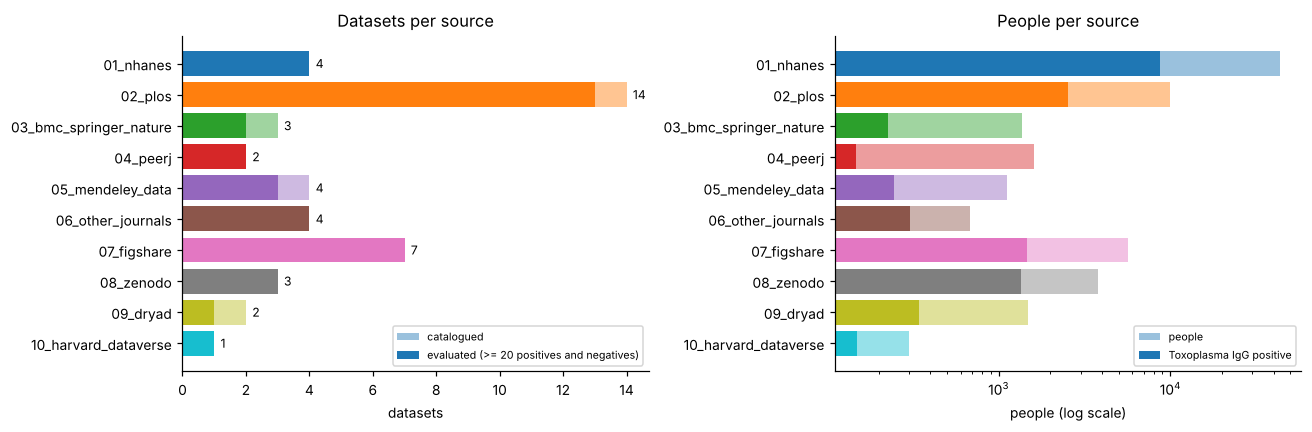

,source,datasets,evaluated,people,positives
0,01_nhanes,4,4,43664,8743
1,02_plos,14,13,10002,2527
2,03_bmc_springer_nature,3,2,1360,228
3,04_peerj,2,2,1598,148
4,05_mendeley_data,4,3,1119,247
5,06_other_journals,4,4,680,303
6,07_figshare,7,7,5697,1458
7,08_zenodo,3,3,3806,1355
8,09_dryad,2,1,1490,343
9,10_harvard_dataverse,1,1,300,150


In [2]:
per = A.groupby('source').agg(datasets=('dataset', 'size'), evaluated=('best_auc', lambda s: s.notna().sum()),
                              people=('n', 'sum'), positives=('positives', 'sum')).reset_index()
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
ax[0].barh(per.source, per.datasets, color=[COL[s] for s in per.source], alpha=0.45, label='catalogued')
ax[0].barh(per.source, per.evaluated, color=[COL[s] for s in per.source], label='evaluated (>= 20 positives and negatives)')
for i, r in per.iterrows(): ax[0].text(r.datasets + 0.2, i, str(r.datasets), va='center', fontsize=8)
ax[0].invert_yaxis(); ax[0].set_xlabel('datasets'); ax[0].set_title('Datasets per source'); ax[0].legend(fontsize=7, loc='lower right')
ax[1].barh(per.source, per.people, color=[COL[s] for s in per.source], alpha=0.45, label='people')
ax[1].barh(per.source, per.positives, color=[COL[s] for s in per.source], label='Toxoplasma IgG positive')
ax[1].set_xscale('log'); ax[1].invert_yaxis(); ax[1].set_xlabel('people (log scale)'); ax[1].set_title('People per source')
ax[1].legend(fontsize=7, loc='lower right')
plt.tight_layout(); save('01_collected'); plt.show()
per

## 2. Size and prevalence of every dataset

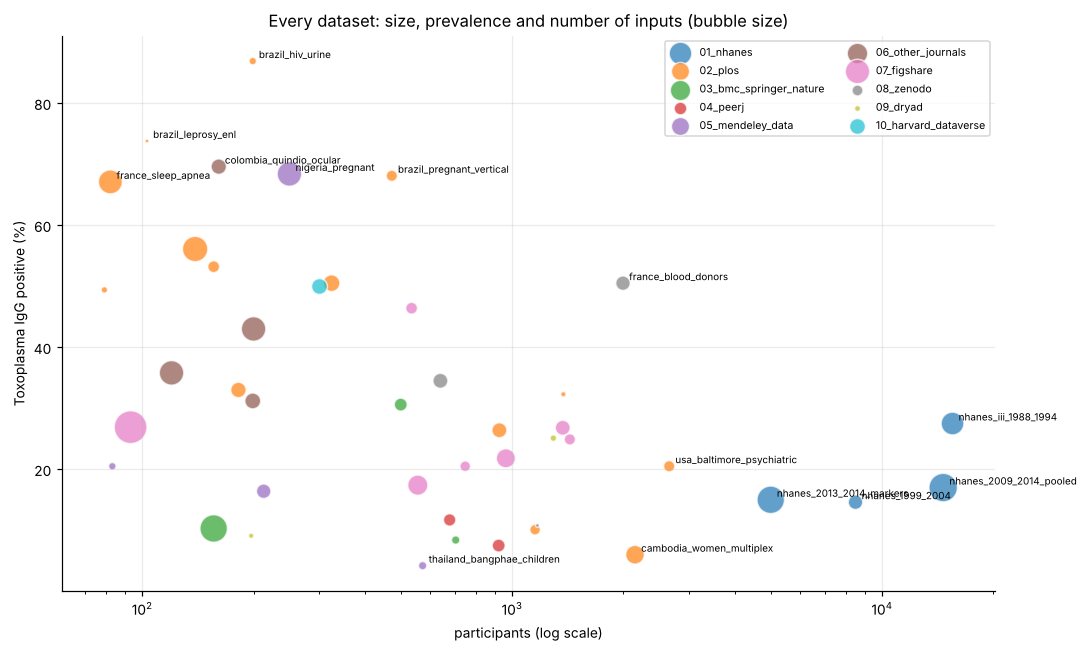

In [3]:
fig, ax = plt.subplots(figsize=(10, 6))
for s in SRC:
    e = A[A.source == s]
    ax.scatter(e.n, e.prevalence * 100, s=np.clip(e.n_features.fillna(1), 1, 80) * 6, color=COL[s], alpha=0.7,
               edgecolor='white', label=s)
for _, r in A.iterrows():
    if r.n > 1500 or r.prevalence > 0.6 or r.prevalence < 0.06:
        ax.annotate(r.dataset, (r.n, r.prevalence * 100), fontsize=6.5, xytext=(4, 2), textcoords='offset points')
ax.set_xscale('log'); ax.set_xlabel('participants (log scale)'); ax.set_ylabel('Toxoplasma IgG positive (%)')
ax.set_title('Every dataset: size, prevalence and number of inputs (bubble size)')
ax.legend(fontsize=7, ncol=2, loc='upper right'); ax.grid(alpha=0.25)
plt.tight_layout(); save('02_size_prevalence'); plt.show()

## 3. Ranking: best ROC-AUC per dataset

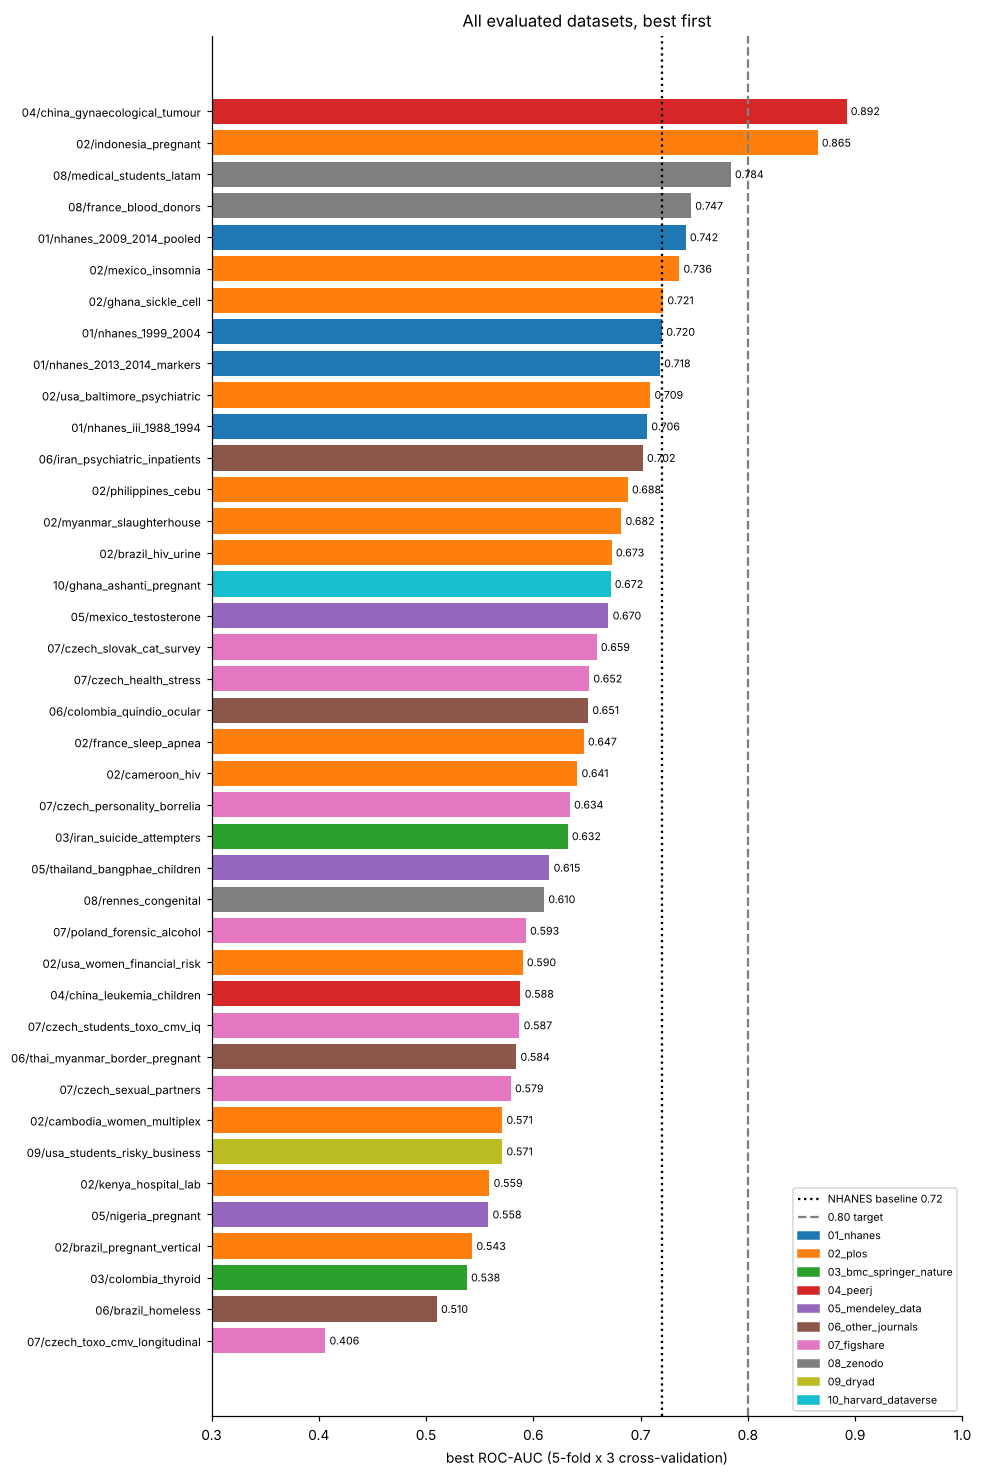

In [4]:
e = EV.sort_values('best_auc')
fig, ax = plt.subplots(figsize=(9, 0.3 * len(e) + 1.5))
ax.barh(range(len(e)), e.best_auc, color=[COL[s] for s in e.source])
for i, v in enumerate(e.best_auc): ax.text(v + 0.004, i, f'{v:.3f}', va='center', fontsize=7)
ax.set_yticks(range(len(e))); ax.set_yticklabels(e.label, fontsize=7.5)
l1 = ax.axvline(0.72, ls=':', color='black', label='NHANES baseline 0.72'); l2 = ax.axvline(0.8, ls='--', color='grey', label='0.80 target')
ax.legend(handles=[l1, l2] + [Patch(color=COL[s], label=s) for s in SRC], fontsize=7, loc='lower right')
ax.set_xlim(0.3, 1.0); ax.set_xlabel('best ROC-AUC (5-fold x 3 cross-validation)'); ax.set_title('All evaluated datasets, best first')
plt.tight_layout(); save('03_ranking'); plt.show()

## 4. Model comparison

Each row is a dataset; the three dots are the three models. Rows where the dots sit together: the model does not matter, the data does.

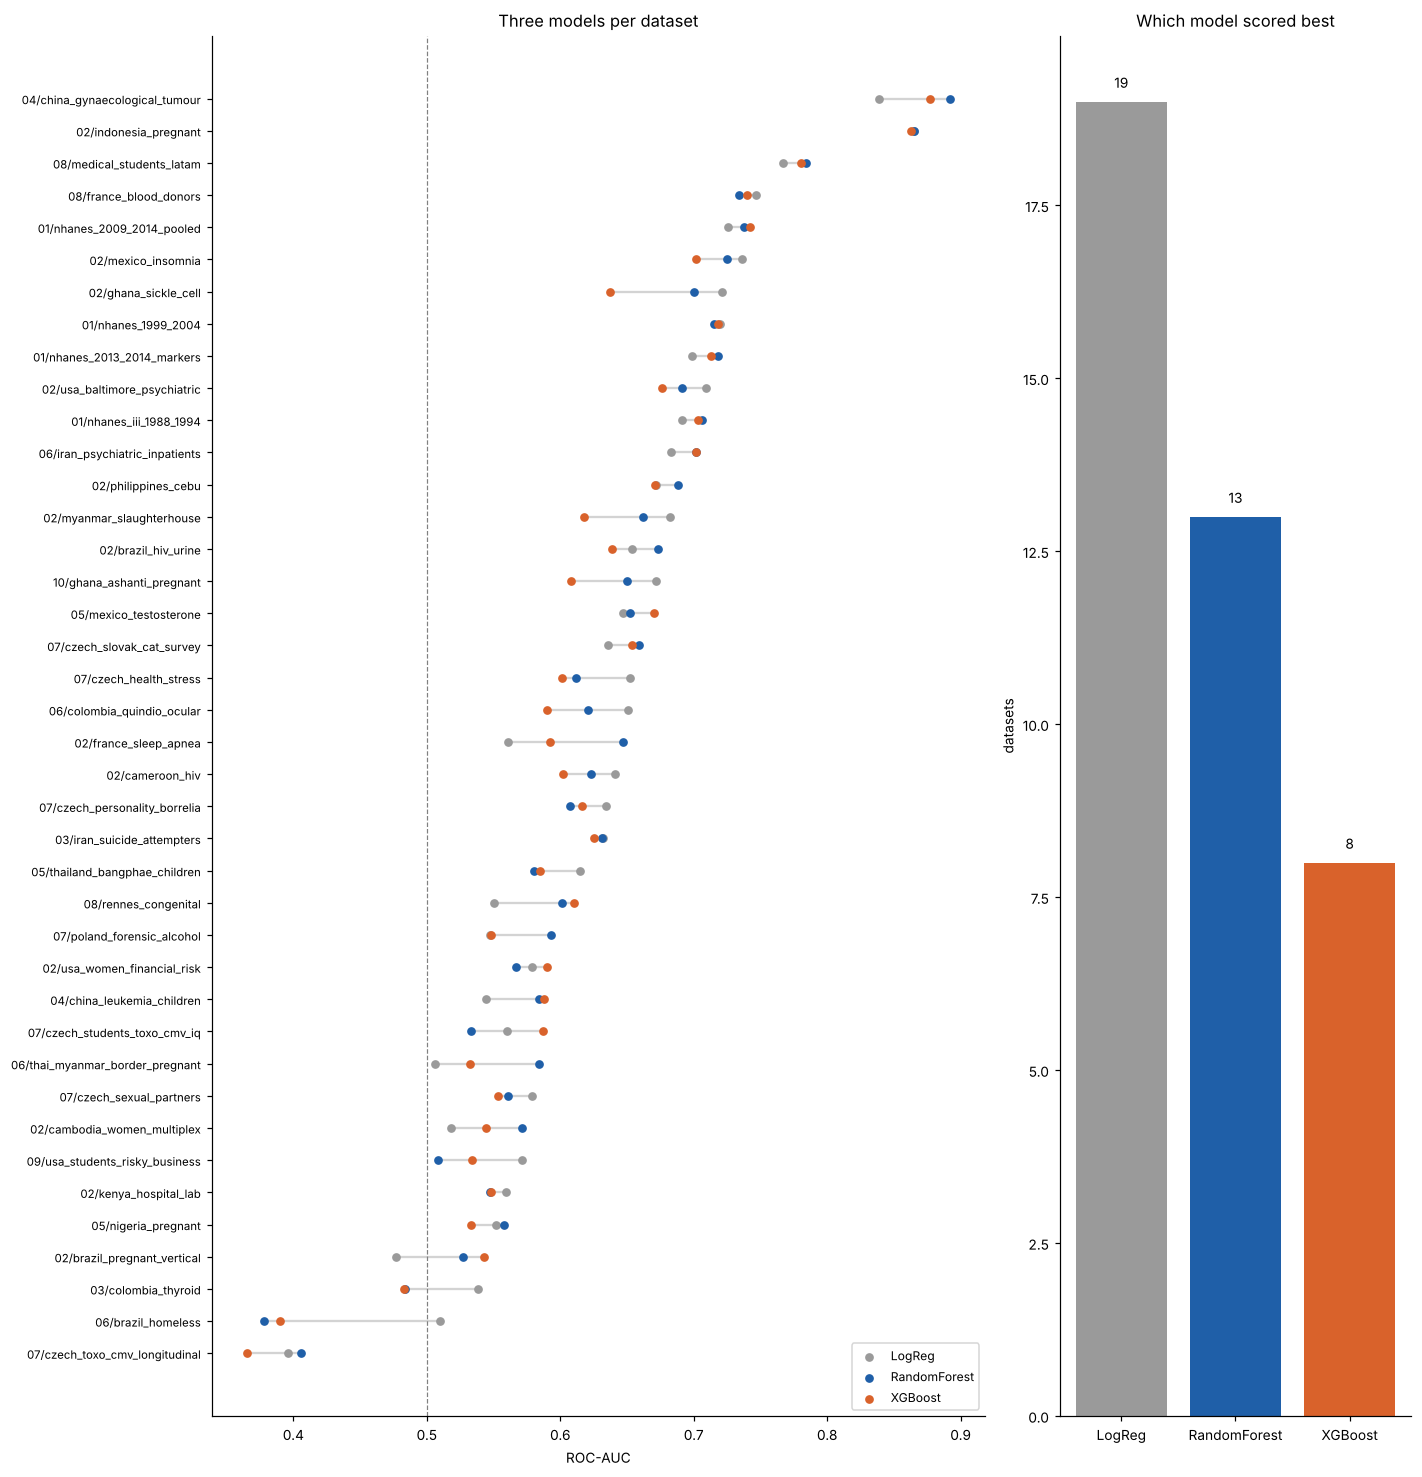

In [5]:
e = EV.sort_values('best_auc')
fig, ax = plt.subplots(1, 2, figsize=(13, 0.3 * len(e) + 1.5), gridspec_kw={'width_ratios': [2.2, 1]})
for m, c in [('LogReg', '#9a9a9a'), ('RandomForest', '#1f5fa8'), ('XGBoost', '#d9622b')]:
    ax[0].scatter(e[f'{m}_auc'], range(len(e)), color=c, s=22, label=m, zorder=3)
ax[0].hlines(range(len(e)), e[['LogReg_auc', 'RandomForest_auc', 'XGBoost_auc']].min(1),
             e[['LogReg_auc', 'RandomForest_auc', 'XGBoost_auc']].max(1), color='lightgrey', zorder=1)
ax[0].set_yticks(range(len(e))); ax[0].set_yticklabels(e.label, fontsize=7.5); ax[0].axvline(0.5, ls='--', color='grey', lw=0.8)
ax[0].set_xlabel('ROC-AUC'); ax[0].legend(fontsize=8, loc='lower right'); ax[0].set_title('Three models per dataset')
wins = EV.best_model.value_counts()
ax[1].bar(wins.index, wins.values, color=[{'LogReg': '#9a9a9a', 'RandomForest': '#1f5fa8', 'XGBoost': '#d9622b'}[k] for k in wins.index])
ax[1].set_title('Which model scored best'); ax[1].set_ylabel('datasets')
for i, v in enumerate(wins.values): ax[1].text(i, v + 0.2, str(v), ha='center')
plt.tight_layout(); save('04_models'); plt.show()

## 5. Score vs dataset size

Error bars = SD of the best model over the 15 CV folds. Small datasets scatter widely; large population datasets settle near 0.70-0.74.

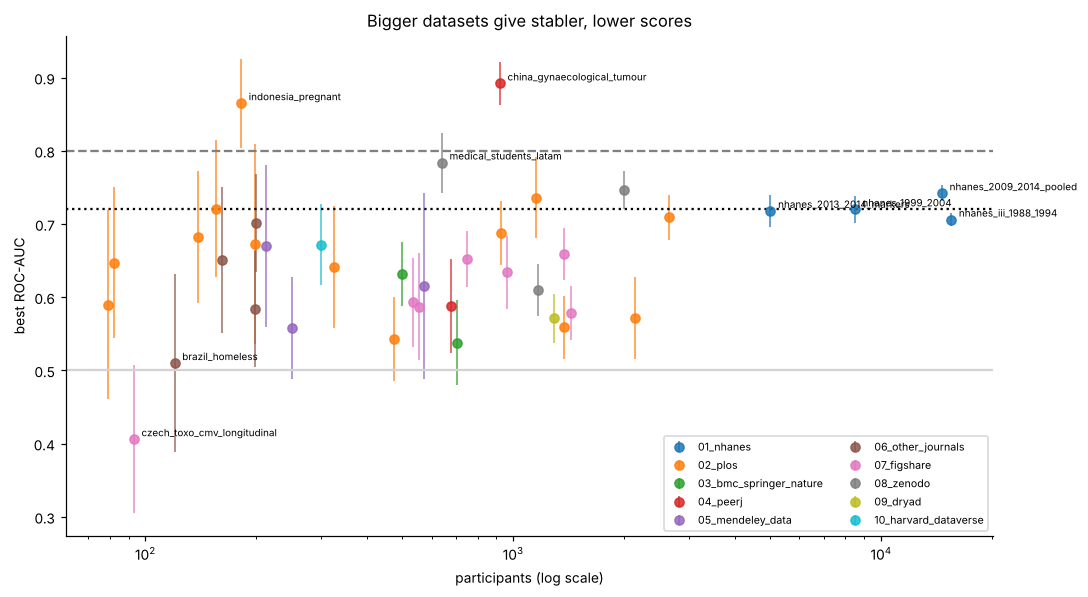

In [6]:
fig, ax = plt.subplots(figsize=(10, 5.5))
for s in SRC:
    e = EV[EV.source == s]
    sd = [r[f'{r.best_model}_sd'] for _, r in e.iterrows()]
    ax.errorbar(e.n, e.best_auc, yerr=sd, fmt='o', color=COL[s], ms=6, elinewidth=1, alpha=0.85, label=s)
for _, r in EV.iterrows():
    if r.best_auc > 0.76 or r.n > 4000 or r.best_auc < 0.52:
        ax.annotate(r.dataset, (r.n, r.best_auc), fontsize=6.5, xytext=(5, 2), textcoords='offset points')
ax.axhline(0.72, ls=':', color='black'); ax.axhline(0.8, ls='--', color='grey'); ax.axhline(0.5, ls='-', color='lightgrey')
ax.set_xscale('log'); ax.set_xlabel('participants (log scale)'); ax.set_ylabel('best ROC-AUC')
ax.set_title('Bigger datasets give stabler, lower scores'); ax.legend(fontsize=7, ncol=2, loc='lower right')
plt.tight_layout(); save('05_score_vs_size'); plt.show()

## 6. What each dataset asks about

Inputs grouped by topic using their column names (after leakage removal). Direct exposure questions (cats, raw meat, soil, water, raw vegetables) are what NHANES 2009-2014 lacks.

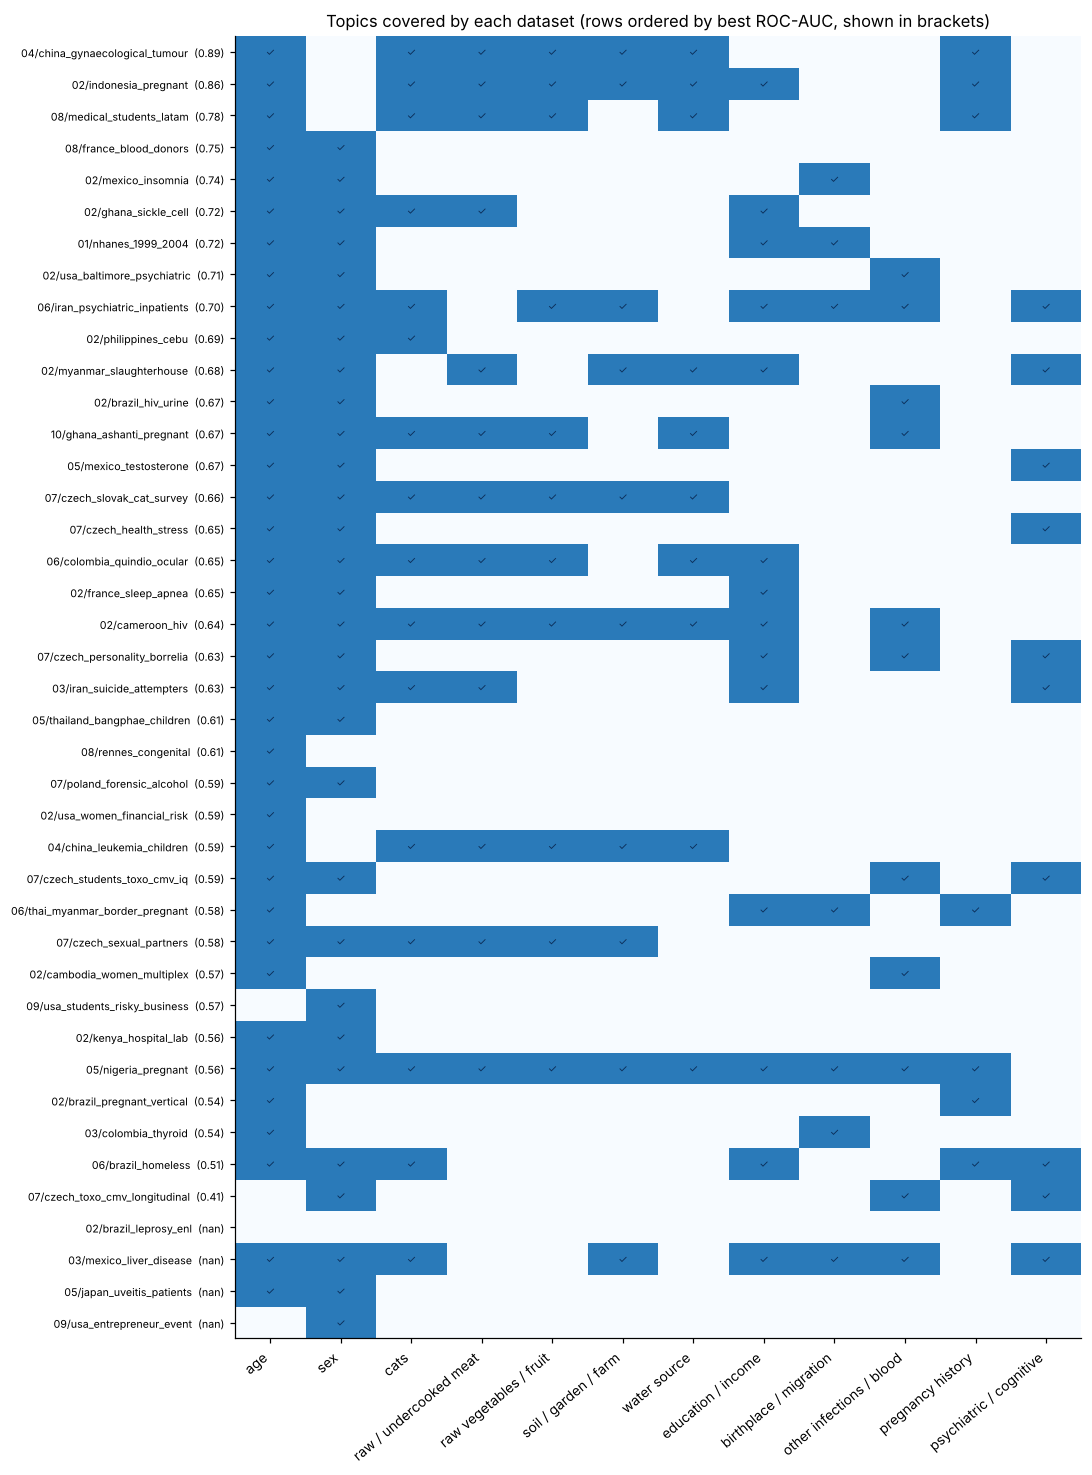

Datasets with at least 3 direct-exposure topics (cats, meat, vegetables, soil, water):
04/china_gynaecological_tumour    5
02/indonesia_pregnant             5
05/nigeria_pregnant               5
07/czech_slovak_cat_survey        5
04/china_leukemia_children        5
02/cameroon_hiv                   5
10/ghana_ashanti_pregnant         4
08/medical_students_latam         4
07/czech_sexual_partners          4
06/colombia_quindio_ocular        4
06/iran_psychiatric_inpatients    3
02/myanmar_slaughterhouse         3


In [7]:
TOPICS = {
    'age': r'\bage|edad|ridageyr|age_', 'sex': r'\bsex|gender|male|sexo|genero',
    'cats': r'(^|[^a-z])cat|gato|litter|feline', 'raw / undercooked meat': r'meat|carne|satay|pork|beef',
    'raw vegetables / fruit': r'vegetable|veg|fruit|frutas|salad', 'soil / garden / farm': r'soil|garden|farm|agricult|suelo',
    'water source': r'water|agua|wat\b|drink', 'education / income': r'educ|income|poverty|pir|sisben|socio|school|literate',
    'birthplace / migration': r'born|birth|migra|citizen|nacim|refugee|ethnic|race|nation',
    'other infections / blood': r'hiv|hsv|cmv|hep|wbc|rbc|hgb|lymph|neut|cd4|eosin|cmv|borrel|malaria|strongy|filar|cyst',
    'pregnancy history': r'pregn|abort|gravid|parity|trimester|miscarr|still',
    'psychiatric / cognitive': r'iq|memory|anx|stress|depress|psych|suicid|personal|intellig|cognit|disgust|scl|stroop'}
rows = {}
for p in sorted(glob.glob('datasets/[0-9]*_*/processed/*.csv')):
    key = p.split('/')[1][:2] + '/' + os.path.basename(p)[:-4]
    cols = [c.lower() for c in pd.read_csv(p, nrows=1).columns if c != 'target_toxo_pos']
    rows[key] = {t: int(any(__import__('re').search(pat, c) for c in cols)) for t, pat in TOPICS.items()}
M = pd.DataFrame(rows).T
M = M.loc[[k for k in EV.sort_values('best_auc', ascending=False).label if k in M.index] + [k for k in M.index if k not in set(EV.label)]]
fig, ax = plt.subplots(figsize=(10, 0.28 * len(M) + 2))
ax.imshow(M.values, cmap='Blues', aspect='auto', vmin=0, vmax=1.4)
ax.set_xticks(range(M.shape[1])); ax.set_xticklabels(M.columns, rotation=40, ha='right')
ax.set_yticks(range(len(M))); ax.set_yticklabels([f"{k}  ({A.set_index('label').best_auc.get(k, np.nan):.2f})" for k in M.index], fontsize=7)
ax.set_title('Topics covered by each dataset (rows ordered by best ROC-AUC, shown in brackets)')
for i in range(M.shape[0]):
    for j in range(M.shape[1]):
        if M.values[i, j]: ax.text(j, i, '✓', ha='center', va='center', fontsize=7, color='#0b2e59')
plt.tight_layout(); save('06_topic_coverage'); plt.show()
print('Datasets with at least 3 direct-exposure topics (cats, meat, vegetables, soil, water):')
direct = M[['cats', 'raw / undercooked meat', 'raw vegetables / fruit', 'soil / garden / farm', 'water source']].sum(1)
print(direct[direct >= 3].sort_values(ascending=False).to_string())

## 7. Strongest single predictors across all datasets

For every numeric input, its ROC-AUC on its own (how well that one column separates positives from negatives; values below 0.5 are flipped, the arrow shows the direction). Top 30 across all evaluated datasets.

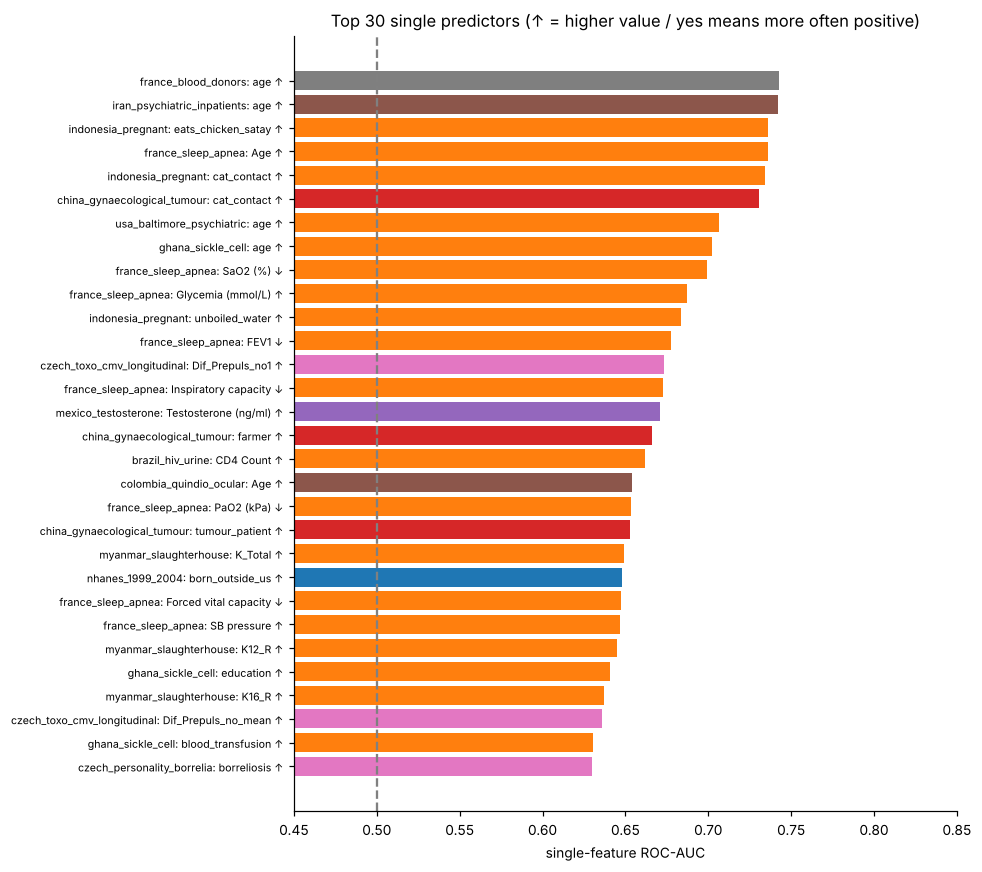

,dataset,feature,auc,higher_is_risk,n
513,08/france_blood_donors,age,0.742670,True,1995
305,06/iran_psychiatric_inpatients,age,0.741942,True,200
129,02/indonesia_pregnant,eats_chicken_satay,0.736339,True,182
65,02/france_sleep_apnea,Age,0.736027,True,82
126,02/indonesia_pregnant,cat_contact,0.734290,True,182
225,04/china_gynaecological_tumour,cat_contact,0.730513,True,920
196,02/usa_baltimore_psychiatric,age,0.706572,True,2641
105,02/ghana_sickle_cell,age,0.702014,True,156
103,02/france_sleep_apnea,SaO2 (%),0.698990,False,82
88,02/france_sleep_apnea,Glycemia (mmol/L),0.687027,True,70


In [8]:
single = []
for p in sorted(glob.glob('datasets/[0-9]*_*/processed/*.csv')):
    key = p.split('/')[1][:2] + '/' + os.path.basename(p)[:-4]
    if key not in set(EV.label): continue
    d = pd.read_csv(p); y = d.pop('target_toxo_pos')
    for c in d.columns:
        x = pd.to_numeric(d[c], errors='coerce'); m = x.notna()
        if m.sum() < 30 or x[m].nunique() < 2 or y[m].nunique() < 2: continue
        a = roc_auc_score(y[m], x[m])
        single.append(dict(dataset=key, feature=c, auc=max(a, 1 - a), higher_is_risk=a >= 0.5, n=int(m.sum())))
S = pd.DataFrame(single).sort_values('auc', ascending=False)
top = S.head(30).iloc[::-1]
fig, ax = plt.subplots(figsize=(9, 8))
ax.barh(range(len(top)), top.auc, color=[COL['0' + d[:1] + d[1:2] if False else [s for s in SRC if s.startswith(d[:2])][0]] for d in top.dataset])
ax.set_yticks(range(len(top))); ax.set_yticklabels([f"{r.dataset.split('/')[1]}: {r.feature[:38]} {'↑' if r.higher_is_risk else '↓'}" for _, r in top.iterrows()], fontsize=7)
ax.axvline(0.5, color='grey', ls='--'); ax.set_xlim(0.45, 0.85); ax.set_xlabel('single-feature ROC-AUC')
ax.set_title('Top 30 single predictors (↑ = higher value / yes means more often positive)')
plt.tight_layout(); save('07_single_predictors'); plt.show()
S.head(30)

## 8. Inside the two top datasets

Percent positive among people who answered yes vs no to each yes/no question, with the number of people in each group.

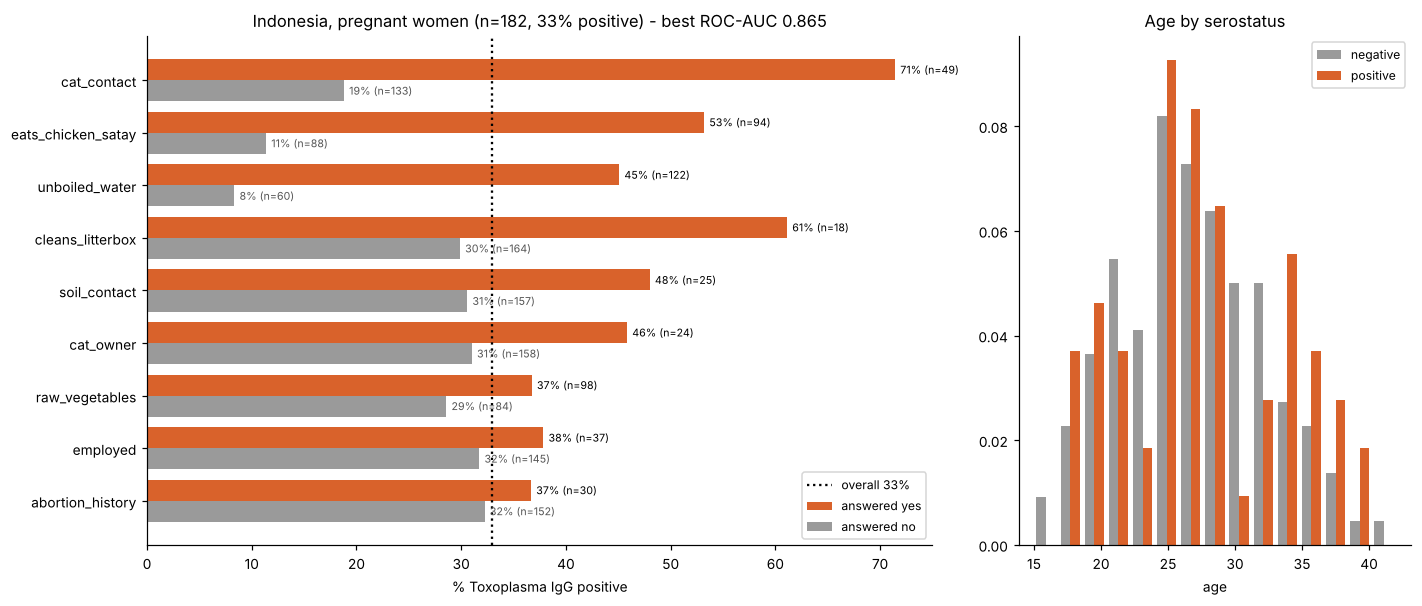

,feature,yes,no,n_yes,n_no,diff
0,abortion_history,36.7,32.2,30,152,4.4
1,employed,37.8,31.7,37,145,6.1
7,raw_vegetables,36.7,28.6,98,84,8.2
2,cat_owner,45.8,31.0,24,158,14.8
5,soil_contact,48.0,30.6,25,157,17.4
4,cleans_litterbox,61.1,29.9,18,164,31.2
8,unboiled_water,45.1,8.3,122,60,36.7
6,eats_chicken_satay,53.2,11.4,94,88,41.8
3,cat_contact,71.4,18.8,49,133,52.6


In [9]:
def inside(path, title, name):
    d = pd.read_csv(path); y = d.target_toxo_pos
    binary = [c for c in d.columns if c != 'target_toxo_pos' and set(d[c].dropna().unique()) <= {0, 1}]
    r = pd.DataFrame([dict(feature=c, yes=100 * y[d[c] == 1].mean(), no=100 * y[d[c] == 0].mean(), n_yes=int((d[c] == 1).sum()),
                           n_no=int((d[c] == 0).sum())) for c in binary]).assign(diff=lambda t: t.yes - t.no).sort_values('diff')
    fig, ax = plt.subplots(1, 2, figsize=(13, 0.42 * len(r) + 1.8), gridspec_kw={'width_ratios': [2, 1]})
    yy = np.arange(len(r))
    ax[0].barh(yy + 0.2, r.yes, 0.4, color='#d9622b', label='answered yes'); ax[0].barh(yy - 0.2, r.no, 0.4, color='#9a9a9a', label='answered no')
    for i, (_, t) in enumerate(r.iterrows()):
        ax[0].text(t.yes + 0.5, i + 0.2, f'{t.yes:.0f}% (n={t.n_yes})', va='center', fontsize=7)
        ax[0].text(t.no + 0.5, i - 0.2, f'{t.no:.0f}% (n={t.n_no})', va='center', fontsize=7, color='#555')
    ax[0].axvline(100 * y.mean(), ls=':', color='black', label=f'overall {100 * y.mean():.0f}%')
    ax[0].set_yticks(yy); ax[0].set_yticklabels(r.feature); ax[0].set_xlabel('% Toxoplasma IgG positive'); ax[0].legend(fontsize=8)
    ax[0].set_title(title)
    ax[1].hist([d.age[y == 0], d.age[y == 1]], bins=15, color=['#9a9a9a', '#d9622b'], label=['negative', 'positive'], density=True)
    ax[1].set_xlabel('age'); ax[1].set_title('Age by serostatus'); ax[1].legend(fontsize=8)
    plt.tight_layout(); save(name); plt.show()
    return r.round(1)

inside('datasets/02_plos/processed/indonesia_pregnant.csv', 'Indonesia, pregnant women (n=182, 33% positive) - best ROC-AUC 0.865',
       '08a_inside_indonesia')

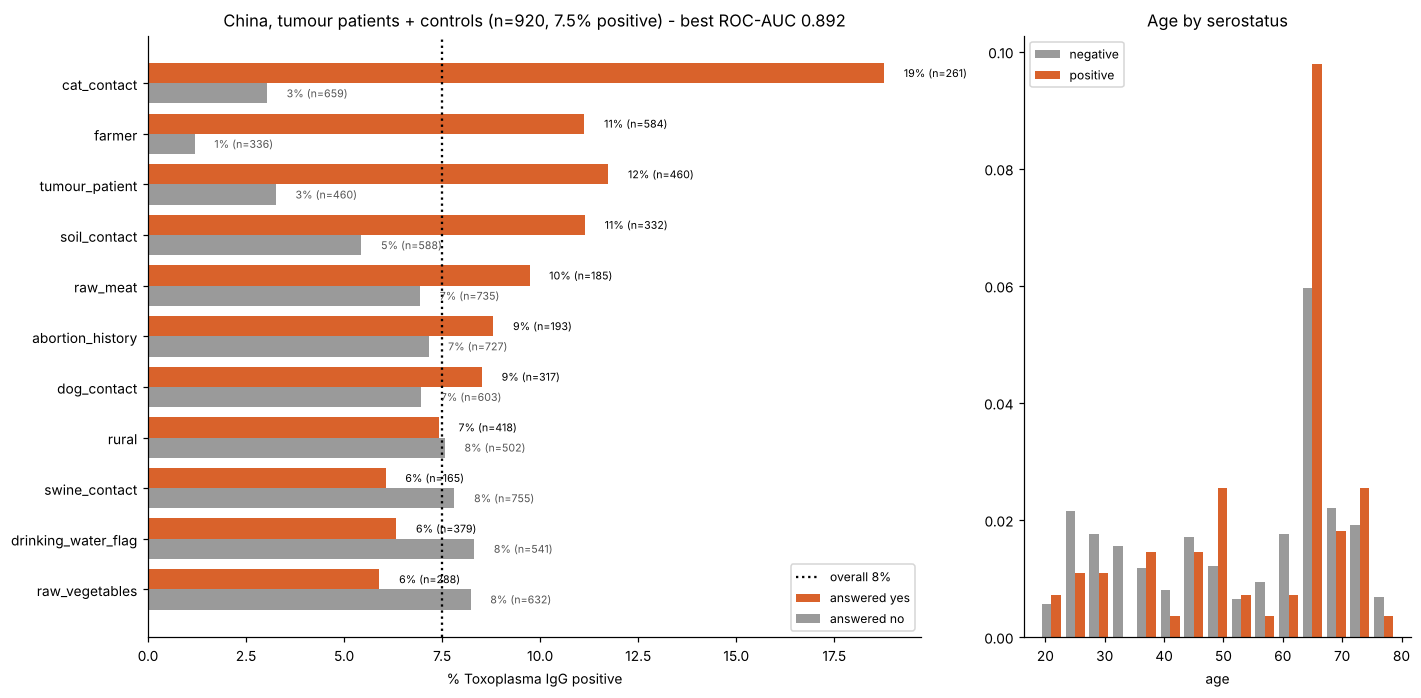

,feature,yes,no,n_yes,n_no,diff
6,raw_vegetables,5.9,8.2,288,632,-2.3
8,drinking_water_flag,6.3,8.3,379,541,-2.0
4,swine_contact,6.1,7.8,165,755,-1.8
1,rural,7.4,7.6,418,502,-0.2
3,dog_contact,8.5,7.0,317,603,1.6
9,abortion_history,8.8,7.2,193,727,1.7
5,raw_meat,9.7,6.9,185,735,2.8
7,soil_contact,11.1,5.4,332,588,5.7
0,tumour_patient,11.7,3.3,460,460,8.5
10,farmer,11.1,1.2,584,336,9.9


In [10]:
inside('datasets/04_peerj/processed/china_gynaecological_tumour.csv',
       'China, tumour patients + controls (n=920, 7.5% positive) - best ROC-AUC 0.892', '08b_inside_china')

**Reading the China chart:** `tumour_patient` is the biggest gap (11.7% vs 3.3% positive) - the 0.892 comes largely from the case-control design, not from a screening signal. Indonesia's high score comes from the exposure questions themselves.